# Operaciones de aprendizaje automático
## Maestría en Inteligencia Artificial Aplicada

### TC5061 | Proyecto MiBici: propuesta y base reproducible | Colaborativo

#### **Equipo:** 7
#### **Nombre:** Fernando Arreola Treviño
#### **Matrícula:** A01840331

## Objetivo
Notebook de **exploración** del proyecto MiBici: carga y descripción del dataset de viajes ya consolidado en Parquet, análisis exploratorio de datos (EDA) y evidencia para las decisiones de limpieza que acordará el equipo.

La pregunta que me corresponde es la **P2 (clasificación)**: ¿Una estación estará en riesgo de quedarse sin bicicletas o sin anclajes disponibles en un periodo futuro?

La lógica que se reutilice se trasladará al módulo del proyecto; en este notebook se desarrolla y se documenta la evidencia que la justifica.

## Dataset
**Datos abiertos de MiBici**, el sistema de bicicleta pública del Área Metropolitana de Guadalajara. El portal publica:
- **Viajes por mes** (`datos_abiertos_AAAA_MM.csv`) desde diciembre de 2014. Cada registro es un viaje con identificador, datos del usuario, fecha y hora de inicio y fin, y estaciones de origen y destino.
- **Nomenclatura de estaciones** (`nomenclatura_AAAA_MM.csv`) con identificador, nombre, latitud, longitud y capacidad de cada estación.

- Fuente: [Datos abiertos de MiBici](https://mibici.net/es/datos-abiertos/)
- Rango analizado: **enero de 2020 a septiembre de 2026**, acordado por el equipo para homologar el EDA. Puede recortarse después con base en los hallazgos. El portal ya no publica 2023-04 ni 2023-05 (ver la decisión de EDA en 1.1).

Se cuenta con lógica implementada para descargar los archivos en un rango especificado y en formato parquet, homologando la codificación y estandarización de fechas (`dataset.py`). Se usó este código para descargar los datos del 2020 al 2026 en la carpeta data/external. Los datos de abril y mayo del 2023 no se descargaron para este análisis debido a que en el momento de su desarrollo (14/10/2026) no estaban disponibles en la página.

In [8]:
import pandas as pd
import numpy as np
import matplotlib
import sys
import pyarrow
from datetime import date
from pathlib import Path
import matplotlib.pyplot as plt
from pathlib import Path
import re

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             log_loss, precision_recall_curve)

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("pyarrow     :", pyarrow.__version__)
print("matplotlib  :", matplotlib.__version__)

Python      : 3.11.5
pandas      : 3.0.5
numpy       : 1.26.4
pyarrow     : 25.0.1
matplotlib  : 3.11.2


## Configuración global


In [9]:
# Rutas del proyecto (el notebook se ejecuta desde notebooks/)
RUTA_PROYECTO = Path.cwd().parent
DATA_DIR = RUTA_PROYECTO / "data" / "external"

# Horas sin servicio de MiBici
SIN_SERVICIO = [1, 2, 3, 4]

SEMILLA = 42

## Carga y descripción de datos

Se definieron funciones para cargar archivos a partir del año o rango especificado. Por conveniencia, también se definió una función que carga todos los archivos. Se incluye también en cada record el archivo de origen.

In [10]:
def leer_archivos_de_un_anio(direccion, anio):
    """Leer todos los archivos parquet de un año particular"""
    folder_path = Path(direccion)

    df = pd.concat(
        [
            pd.read_parquet(file).assign(file_name=file.name)
            for file in folder_path.glob(f"*_{anio}_*.parquet")
        ],
        ignore_index=True
    )

    return df

def leer_todos_los_archivos(direccion):
    """Leer todos los archivos parquet disponibles en una dirección"""
    folder_path = Path(direccion)

    df = pd.concat(
        [
            pd.read_parquet(file).assign(file_name=file.name)
            for file in folder_path.glob("*.parquet")
        ],
        ignore_index=True
    )

    return df

def leer_rango(direccion, desde=(2014, 12), hasta=(9999, 12), columnas=None):
    """Leer todos los archivos en un rango de fechas especificado"""
    patron = re.compile(r"datos_abiertos_(\d{4})_(\d{2})\.parquet$")
    archivos = []
    for ruta in sorted(Path(direccion).glob("datos_abiertos_*.parquet")):
        m = patron.search(ruta.name)
        if m and desde <= (int(m[1]), int(m[2])) <= hasta:
            archivos.append(ruta)
    if not archivos:
        raise FileNotFoundError(f"No hay Parquet entre {desde} y {hasta} en '{direccion}'")
    
    df = pd.concat(
        [
            pd.read_parquet(r, columns=columnas).assign(nombre_archivo=r.name) for r in archivos
        ],
        ignore_index=True)

    return df

El rango escogido a analizar es de enero del 2020 a septiembre del 2026.

In [11]:
df = leer_rango(DATA_DIR, (2020, 1), (2026, 9))

Se describe el dataframe: nombres de columnas, tipo de datos, conteo de valores no nulos.

In [12]:
df.info(show_counts=True, memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 27086557 entries, 0 to 27086556
Data columns (total 9 columns):
 #   Column              Non-Null Count     Dtype         
---  ------              --------------     -----         
 0   viaje_id            27086557 non-null  Int64         
 1   usuario_id          27086557 non-null  Int64         
 2   genero              26948912 non-null  str           
 3   anio_de_nacimiento  27051936 non-null  Int64         
 4   inicio_del_viaje    27086557 non-null  datetime64[us]
 5   fin_del_viaje       27086557 non-null  datetime64[us]
 6   origen_id           27086557 non-null  Int64         
 7   destino_id          27086557 non-null  Int64         
 8   nombre_archivo      27086557 non-null  str           
dtypes: Int64(5), datetime64[us](2), str(2)
memory usage: 2.7 GB


## Exploración de los datos

Existen 758 records duplicados. Estos se eliminan:

In [13]:
df.duplicated().sum()

758

In [14]:
df[df.duplicated(keep=False)].head(10)

,viaje_id,usuario_id,genero,anio_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,nombre_archivo
26596633,45705948,4610130,M,2001,2026-09-01 05:42:47,2026-09-01 06:02:02,265,303,datos_abiertos_2026_09.parquet
26596634,45705948,4610130,M,2001,2026-09-01 05:42:47,2026-09-01 06:02:02,265,303,datos_abiertos_2026_09.parquet
26597455,45706846,4610130,M,2001,2026-09-01 07:11:03,2026-09-01 07:29:32,303,265,datos_abiertos_2026_09.parquet
26597456,45706846,4610130,M,2001,2026-09-01 07:11:03,2026-09-01 07:29:32,303,265,datos_abiertos_2026_09.parquet
26597863,45707318,1110472,F,1992,2026-09-01 07:37:33,2026-09-01 07:42:47,102,105,datos_abiertos_2026_09.parquet
26597864,45707318,1110472,F,1992,2026-09-01 07:37:33,2026-09-01 07:42:47,102,105,datos_abiertos_2026_09.parquet
26597883,45707337,4610243,M,1972,2026-09-01 07:38:39,2026-09-01 07:51:52,363,445,datos_abiertos_2026_09.parquet
26597884,45707337,4610243,M,1972,2026-09-01 07:38:39,2026-09-01 07:51:52,363,445,datos_abiertos_2026_09.parquet
26598204,45707670,1163105,F,1987,2026-09-01 07:53:10,2026-09-01 08:18:27,434,217,datos_abiertos_2026_09.parquet
26598205,45707670,1163105,F,1987,2026-09-01 07:53:10,2026-09-01 08:18:27,434,217,datos_abiertos_2026_09.parquet


In [15]:
df = df.drop_duplicates()

Se visualiza el número de viajes por mes:

In [16]:
def redondear_a_primer_dia_del_mes(dt_col):
    """Redondear fechas en formato ISO8061 al primer día del mes más cercano"""
    col_redondeado = dt_col.astype(str).str.slice(stop=8) + "01"
    return pd.to_datetime(col_redondeado)

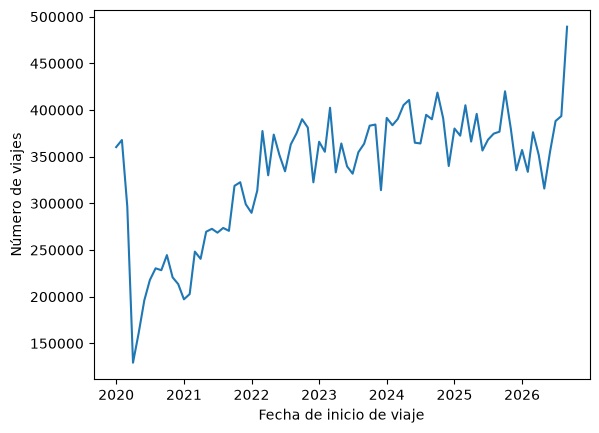

In [17]:
groupedby = df.groupby(redondear_a_primer_dia_del_mes(df["inicio_del_viaje"]))['viaje_id'].count()

plt.plot(groupedby.index, groupedby)
plt.xlabel("Fecha de inicio de viaje")
plt.ylabel("Número de viajes")
plt.show()

Se calcula el número de valores nulos:

In [18]:
# Solo Genero y Año de nacimiento tienen nulls
df.isna().sum()

viaje_id                   0
usuario_id                 0
genero                137645
anio_de_nacimiento     34621
inicio_del_viaje           0
fin_del_viaje              0
origen_id                  0
destino_id                 0
nombre_archivo             0
dtype: int64

Se analiza si existe correlación entre Género y Año de Nacimiento en cuanto a su distribución. La correlación obtenida es baja, y por lo tanto no existe correlación entre la distribución de nulos de ambas columnas.

In [19]:
# No hay correlacion entre los nulos de Genero y los nulos de año de nacimiento
null_matrix = df[["genero","anio_de_nacimiento"]].isnull().astype(int)
null_corr = null_matrix.corr(method='pearson')
null_corr

,genero,anio_de_nacimiento
genero,1.000000,0.057374
anio_de_nacimiento,0.057374,1.000000


In [20]:
# 26917657 records no tienen ninguna de estas columnas (Genero, Año de nacimiento) nulas
# 164018 tienen una u otra nula
# 4124 tienen ambas nulas
null_matrix.sum(axis=1).value_counts()

0    26917657
1      164018
2        4124
Name: count, dtype: int64

Se analiza el dataframe por tipo de dato:

In [21]:
cat_cols = df.select_dtypes(include=["str","object"]).columns.tolist()
num_cols = df.select_dtypes(include=["number"]).columns.tolist()
time_cols = df.select_dtypes(include=["datetime"]).columns.tolist()
assert len(cat_cols) + len(num_cols) + len(time_cols) == len(df.columns)

Primero se analizan las categóricas:

In [22]:
cat_stats_df = df[cat_cols].describe().T
cat_stats_df

# El archivo 2026_09 es el que tiene más records

,count,unique,top,freq
genero,26948154,2,M,19637659
nombre_archivo,27085799,81,datos_abiertos_2026_09.parquet,489298


Se obtiene la distribución porcentual de género:

In [23]:
df["genero"].value_counts()*100/len(df)

genero
M    72.501679
F    26.990140
Name: count, dtype: float64

Ahora se analizan las numéricas:

In [24]:
num_stats_df = df[num_cols].describe().T
num_stats_df["kurt"] = df[num_cols].kurt()
num_stats_df["skew"] = df[num_cols].skew()
num_stats_df

# Año de nacimiento mínimo de 1 es inusual
# Año de nacimiento máximo de 2023 también

,count,mean,std,min,25%,50%,75%,max,kurt,skew
viaje_id,27085799.0,30524926.982502,9149321.812414,14420217.0,22612617.5,30602778.0,38447984.5,46255558.0,-1.193166,-0.022211
usuario_id,27085799.0,1486053.056477,1428090.138232,102.0,424716.0,770504.0,2237160.0,5006315.0,-0.081696,1.088366
anio_de_nacimiento,27051178.0,1989.058696,16.908096,1.0,1984.0,1992.0,1997.0,2023.0,7619.167007,-67.304276
origen_id,27085799.0,145.121616,105.451899,2.0,51.0,142.0,235.0,519.0,-0.923654,0.445937
destino_id,27085799.0,145.730858,107.716972,2.0,51.0,133.0,247.0,519.0,-0.978102,0.458829


Existen años de nacimiento inusuales; ya sea muy recientes o muy antiguos para ser realistas. Se asume que pudo ser un error de usuario al registrarse en la aplicación. Dado que este problema no requiere un análisis de los usuarios, eliminar estos registros potencialmente implica eliminar viajes válidos. Por lo tanto, se conservan.

Ahora se analizan los IDs. Primero los de viaje:

In [25]:
df["viaje_id"].value_counts().head(100)

viaje_id
14420217    1
14420218    1
14420219    1
14420220    1
14420221    1
           ..
14420327    1
14420328    1
14420329    1
14420330    1
14420333    1
Name: count, Length: 100, dtype: Int64

No existen IDs de viaje duplicados.

Ahora se limpian los IDs de origen y destino. Estos requieren analizar también los IDs de estaciones del archivo de nomenclaturas, y por lo tanto se carga primero:

In [26]:
estaciones_df = pd.read_csv(f"{DATA_DIR}/nomenclatura_estaciones.csv")

In [27]:
estaciones_df.head(10)

,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11
5,8,(GDL-006) C. Venustiano Carranza /C. Reforma,20.680717,-103.344415,11
6,9,(GDL-007) C. Epigmenio Glez./Av. Cristobal C.,20.666771,-103.350562,15
7,10,(GDL-008) C. Ignacio Zaragoza / C. J. Angulo,20.681953,-103.349992,15
8,11,(GDL-009) Calz. Federalismo/ C. J. Angulo,20.682077,-103.353835,23
9,12,(GDL-010) C. Cruz verde / C. Joaquin Angulo,20.681852,-103.357338,15


El problema a analizar requiere analizar la capacidad de cada estación. Por lo tanto, primero se descartan estaciones con capacidad de 0:

In [28]:
estaciones_df = estaciones_df[estaciones_df["dpcapacity"] > 0]

Ahora, en el dataframe de viajes, se descartan records con orígenes y destinos no presentes en el dataframe de estaciones:

In [29]:
# Si un id no está en el archivo de la nomenclatura, no es posible analizarlo para el problema P2. Los records con estos ids se eliminan
def descartar_records_con_id_inexistente_en_nomenclatura(datos_df, estaciones_df, col_origen, col_destino, col_id_nomenclatura):
    datos_df = datos_df.copy()
    origen_id_no_en_nomenclatura = ~(datos_df[col_origen].isin(estaciones_df[col_id_nomenclatura].unique()))
    destino_id_no_en_nomenclatura = ~(datos_df[col_destino].isin(estaciones_df[col_id_nomenclatura].unique()))
    return datos_df[~(origen_id_no_en_nomenclatura | destino_id_no_en_nomenclatura)]

In [30]:
df = descartar_records_con_id_inexistente_en_nomenclatura(df, estaciones_df, "origen_id", "destino_id", "id")

Finalmente, se analizan las columnas de tiempo.

In [31]:
df[time_cols].describe().T

,count,mean,min,25%,50%,75%,max
inicio_del_viaje,27081838,2023-08-28 19:12:50.855628,2020-01-01 06:02:20,2022-03-10 11:58:29.500000,2023-10-06 19:34:10.500000,2025-03-28 17:43:25.250000,2026-09-30 23:59:48
fin_del_viaje,27081838,2023-08-28 19:23:50.901600,2020-01-01 06:05:38,2022-03-10 12:08:37.500000,2023-10-06 19:47:14.500000,2025-03-28 17:54:30.750000,2026-10-01 00:14:52


Ambas variables tienen rangos esperados: primer viaje inició el 1 de enero del 2020, el último viaje inició el 30 de septiembre del 2026. Cabe destacar que algunos de los viajes que iniciaron el 30 de septiembre, concluyeron en las primeras horas del 1 de octubre del 2026. No se desea evaluar la capacidad de las estaciones más allá de septiembre 2026; por lo tanto, se filtran estos records:

In [32]:
# 16 records terminaron después de septiembre 2026
sum(df["fin_del_viaje"] >= '2026-10-01 00:00:00')

16

In [33]:
df = df[df["fin_del_viaje"] < '2026-10-01 00:00:00']

Ahora se evalua si existen registros con duraciones de tiempo no realistas.

In [34]:
df["duracion_del_viaje"] = (df.fin_del_viaje - df.inicio_del_viaje).dt.total_seconds()

In [35]:
df["duracion_del_viaje"].sort_values(ascending=False).head(10) / (60*60*24)

3292526     19.549144
108473      17.210660
4042178     16.863264
3897347     12.031111
2380157      9.731296
21696906     7.986644
1966431      7.584236
1979978      6.221910
3972143      5.378160
1980304      4.930231
Name: duracion_del_viaje, dtype: float64

In [36]:
df["duracion_del_viaje"].sort_values(ascending=True).head(10)

13629761    0.0
5582636     0.0
14482537    0.0
2329957     0.0
5584138     0.0
12158101    0.0
14480218    0.0
12158534    0.0
2155998     0.0
2156008     0.0
Name: duracion_del_viaje, dtype: float64

Algunos viajes muestran duraciones de tiempo inusuales. Los 10 registros más comunes muestran duraciones de alrededor de 5 días o más. El más extenso duró más de 19 días. Aunque no son realistas, no son imposibles y por lo tanto se conservan.

Cabe destacar que la duración mínima de viajes es de 0. Por lo tanto, no existen casos donde inicio_del_viaje > fin_del_viaje. Esto se puede validar: 

In [37]:
df[df["inicio_del_viaje"] > df["fin_del_viaje"]]

,viaje_id,usuario_id,genero,anio_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,nombre_archivo,duracion_del_viaje


In [38]:
df = df.drop("duracion_del_viaje", axis=1)

Finalmente, la página de MiBici que el servicio está habilitado de 5 AM a 12:59 AM. Por lo tantro, se filtran records cuyo inicio de viaje esté fuera de este rango; para este análisis, se consideran anómalos.

In [39]:
df = df[~df["inicio_del_viaje"].dt.hour.isin([1,2,3,4])]

## Preprocesamiento

Para el problema P2, el dataframe de viajes es inapropiado. Para estimar el cambio en capacidad a lo largo del tiempo (y después categorizar si una estación está en riesgo de quedarse sin inventario o sin anclajes), es necesario que cada registro sea un evento (salida o entrada de una bici en una estación). Se define una función para hacer esta conversión.

NOTA IMPORTANTE: Hay dos puntos clave que dificultan el análisis signfificativamente:
- No se cuenta con un estimado de inventario inicial por estación.
- No es realista asumir que en este rango de fechas nunca ocurrió un reabastecimiento, particularmente en los horarios sin servicio.

### Prueba: Conteo con ventana de tiempo

In [40]:
def obtener_dataframe_de_eventos(viajes, estaciones):
    """Convertir dataframe de viajes a dataframe de eventos.
    En el dataframe de eventos, cada registro es una cambio en número de bicicletas para una estación.
    Si sale una bicicleta, delta=-1, si entra una bicicleta, delta=1
    La columna orden se usa para romper empates al momento de calcular la suma acumulada (salida primero, entrada después)
    """
    salidas = pd.DataFrame({"tiempo": viajes["inicio_del_viaje"], "estacion": viajes["origen_id"], "delta": -1, "orden": 0})
    entradas = pd.DataFrame({"tiempo": viajes["fin_del_viaje"], "estacion": viajes["destino_id"], "delta": 1, "orden": 1})
    eventos = pd.concat([salidas, entradas], ignore_index=True)
    eventos = eventos.sort_values(["estacion", "tiempo", "orden"], kind="stable").reset_index(drop=True)
    eventos_con_capacidad = pd.merge(eventos, estaciones[["id","dpcapacity","latitude","longitude"]], how="left", left_on="estacion", right_on="id")
    eventos_con_capacidad = eventos_con_capacidad.drop("id", axis=1)
    eventos_con_capacidad["cumsum"] = eventos_con_capacidad.groupby("estacion")["delta"].cumsum()
    
    return eventos_con_capacidad

eventos_df = obtener_dataframe_de_eventos(df, estaciones_df)

In [41]:
eventos_df.head(10)

,tiempo,estacion,delta,orden,dpcapacity,latitude,longitude,cumsum
0,2020-01-01 08:05:09,2,-1,0,15,20.666378,-103.34882,-1
1,2020-01-01 08:05:19,2,1,1,15,20.666378,-103.34882,0
2,2020-01-01 08:05:30,2,-1,0,15,20.666378,-103.34882,-1
3,2020-01-01 10:01:28,2,1,1,15,20.666378,-103.34882,0
4,2020-01-01 11:15:49,2,1,1,15,20.666378,-103.34882,1
5,2020-01-01 11:18:26,2,-1,0,15,20.666378,-103.34882,0
6,2020-01-01 11:47:41,2,1,1,15,20.666378,-103.34882,1
7,2020-01-01 11:51:18,2,1,1,15,20.666378,-103.34882,2
8,2020-01-01 14:40:22,2,1,1,15,20.666378,-103.34882,3
9,2020-01-01 14:40:29,2,1,1,15,20.666378,-103.34882,4


Se seleccionan aleatoriamente 6 estaciones para observar los cambios de entradas y salidas de bicicletas con el tiempo (con semilla fija por reproducibilidad). Inmediatamente se destaca un problema:

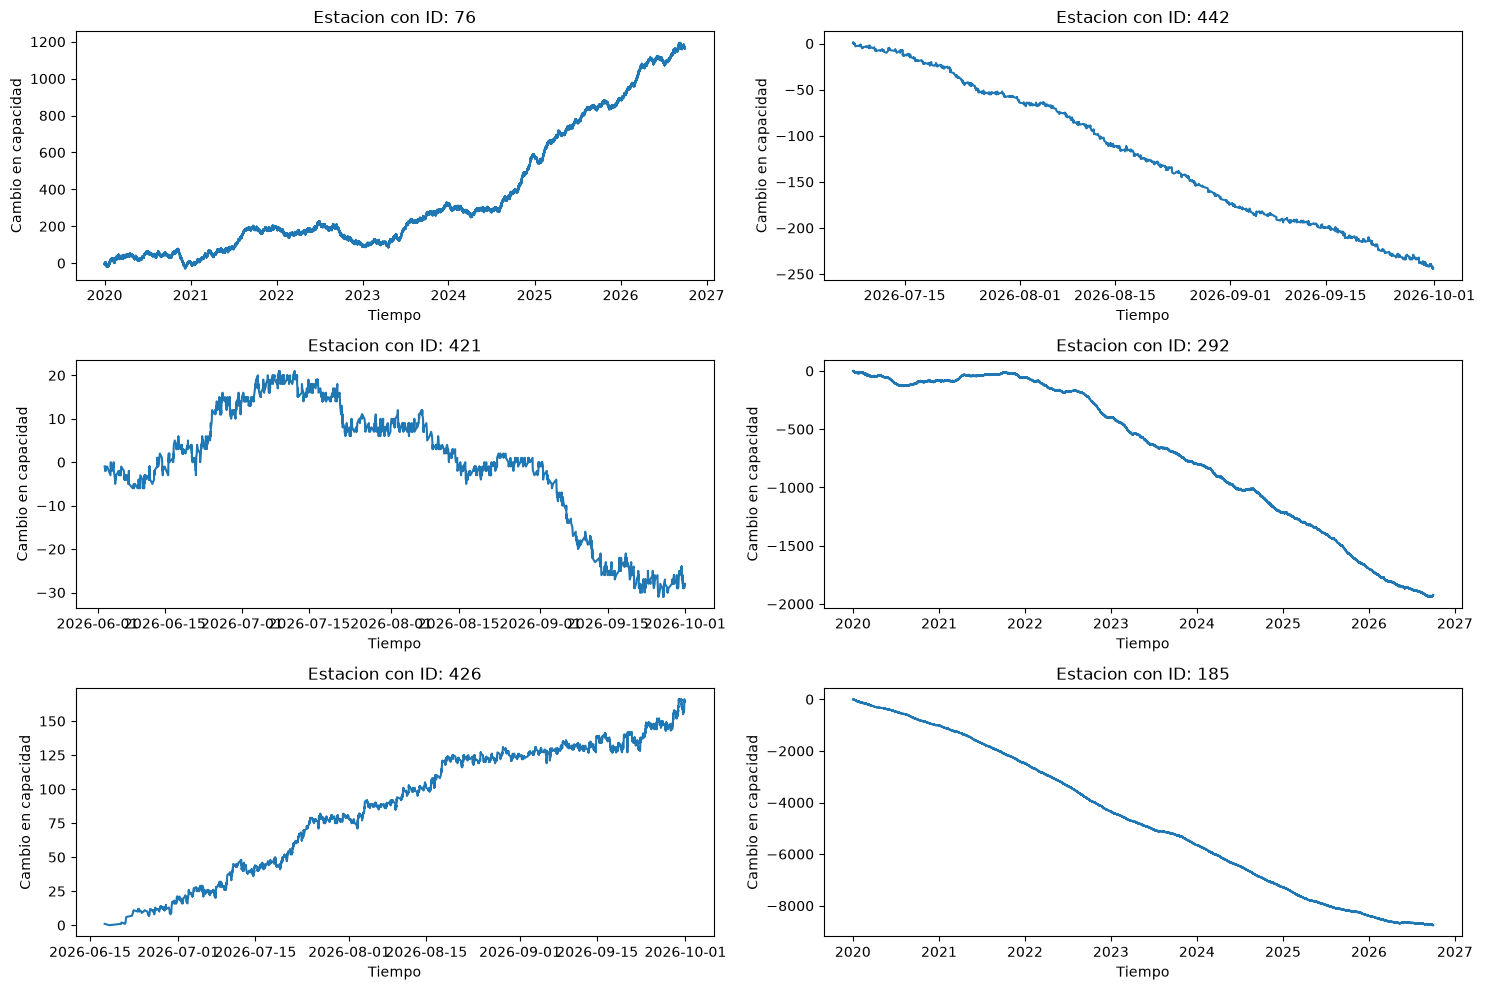

In [42]:
estaciones = estaciones_df["id"].sample(n=6, random_state=SEMILLA)
plt.figure(figsize=(15,10))
for i, estacion in enumerate(estaciones):
    plt.subplot(3,2,i+1)
    eventos_de_estacion = eventos_df[eventos_df["estacion"] == estacion]
    plt.plot(eventos_de_estacion["tiempo"], eventos_de_estacion["cumsum"])
    plt.xlabel("Tiempo")
    plt.ylabel("Cambio en capacidad")
    plt.title(f"Estacion con ID: {estacion}")

plt.tight_layout()
plt.show()

Las estaciones con datos desde el 2020 muestran tendencias que no se mantienen dentro de la capacidad de la estación. Se hace un análisis más exhaustivo a continuación, calculando el rango de la suma acumulada de movimientos y comparándola con la capacidad de cada estación.

In [43]:
rango = eventos_df.groupby("estacion")["cumsum"].agg(lambda s: s.max() - s.min())
cap = estaciones_df.set_index("id")["dpcapacity"].reindex(rango.index)
print("rango (max-min) del cumsum, mediana:", rango.median(), "| capacidad mediana:", cap.median())
print("% de estaciones cuyo cumsum recorre MÁS que su capacidad:", round(100 * (rango > cap).mean(), 1))

rango (max-min) del cumsum, mediana: 4153.5 | capacidad mediana: 15.0
% de estaciones cuyo cumsum recorre MÁS que su capacidad: 99.2


In [44]:
df = df[df["inicio_del_viaje"] >= '2024-01-01']

In [45]:
def intervalo(ts, bin_min):
    b = ts.dt.floor(f"{bin_min}min")
    ultimo = b.dt.floor("D") + pd.Timedelta(hours=1) - pd.Timedelta(minutes=bin_min)
    return b.where(~b.dt.hour.isin(SIN_SERVICIO), ultimo)


In [46]:
def obtener_dataframe_de_eventos_con_bins(viajes, bin_min):
    # Obtener salidas y entradas por intervalo de tiempo y estación
    salidas = viajes.groupby(["origen_id", intervalo(viajes.inicio_del_viaje, bin_min=bin_min)]).size().rename("salidas")
    entradas = viajes.groupby(["destino_id", intervalo(viajes.fin_del_viaje, bin_min=bin_min)]).size().rename("entradas")

    # Unificar salidas y entradas en dataframe de eventos
    salidas.index.names = entradas.index.names = ["estacion", "bin"]
    eventos = pd.concat([salidas, entradas], axis=1).fillna(0).astype("int32")
    
    return eventos

In [47]:
def generar_arreglo_de_bins(eventos, bin_min):
    
    # De la fecha minima a la fecha maxima del dataframe de eventos, con frecuencia de bin_min
    bins = pd.date_range(eventos.index.get_level_values("bin").min().floor("D"),
                     eventos.index.get_level_values("bin").max(), freq=f"{bin_min}min")
    
    # Remover los bins que corresponden a horas sin servicio
    bins = bins[~bins.hour.isin(SIN_SERVICIO)] 
    
    return bins

In [48]:
def obtener_panel_de_eventos(viajes, estaciones, bin_min):
    # Obtener dataframe de eventos
    eventos = obtener_dataframe_de_eventos_con_bins(viajes, bin_min=bin_min)
    
    # Obtener arreglo de bins de tiempo
    bins = generar_arreglo_de_bins(eventos, bin_min=bin_min)
    
    # Expandir eventos para que cada estación tenga records de tiempo con frecuencia de bin_min
    rejilla = pd.MultiIndex.from_product([eventos.index.get_level_values("estacion").unique(), bins], names=["estacion", "bin"])
    panel = eventos.reindex(rejilla, fill_value=0).reset_index()       # los ceros también son filas
    
    # Se calcula el flujo neto de bicicletas (entradas - salidas) y el día de servicio de cada record
    panel["neto"] = panel.entradas - panel.salidas
    panel["dia"] = (panel.bin - pd.Timedelta(hours=5)).dt.floor("D")   # día de servicio: 05:00 -> 00:59
    
    # Se eliminan las combinaciones de estaciones y días sin actividad
    act = panel.groupby(["estacion", "dia"])[["salidas", "entradas"]].transform("sum").sum(axis=1)
    panel = panel[act > 0]
    
    # Agregar datos de estaciones al panel
    panel = panel.merge(estaciones[["id","latitude","longitude","dpcapacity"]], left_on="estacion", right_on="id", how="left")
    panel = panel.drop("id", axis=1) # Quitar la columna de ID que viene del dataframe de estaciones (redundante)
    
    # Ordenar panel por estación y por tiempo discretizado (bins)
    panel = panel.sort_values(["estacion", "bin"]).reset_index(drop=True)
    
    # Calcular suma acumulada de movimientos netos (entradas - salidas) por estación
    panel["cumsum_dia"] = panel.groupby(["estacion", "dia"], sort=False)["neto"].cumsum()
    
    return panel

In [49]:
BIN_MIN = 30
panel = obtener_panel_de_eventos(df, estaciones_df, bin_min=BIN_MIN)
print("panel:", panel.shape)

panel: (14964544, 10)


In [50]:
H_BINS = 4
ALFA = 0.5

def obtener_mayores_cambios_en_proximos_h_bins(panel, h):
    """Peor salida neta y peor entrada neta en los intervalos t+1..t+h (mismo día), como fracción de la capacidad.
    La intención es usar estas mediciones como base para estimar el riesgo de que que una estación se quede sin bicicletas
    o se llene en los próximos h*bin_freq minutos.
    """
    # Obtener suma acumulada de movimiento por estación, por día
    cumsums = panel.groupby(["estacion", "dia"], sort=False)["cumsum_dia"]
    
    # Calcular cambio neto de un tiempo t, al tiempo k
    # Se obtiene una columna por cada valor de k entre t+1 y h (h columnas en total)
    cambios_futuros = pd.concat([cumsums.shift(-k) - panel["cumsum_dia"] for k in range(1, h + 1)], axis=1)
    
    # De los h cambios netos calculados:
    # Se obtiene el más negativo y se guarda en la variable "vacia"
    # Se obtiene el más positivo y se guarda en la variable "llena"
    # Ambas se obtienen como fracción de la capacidad total
    vacia = (-cambios_futuros).max(axis=1, skipna=False).clip(lower=0) / panel["dpcapacity"]
    llena = cambios_futuros.max(axis=1, skipna=False).clip(lower=0) / panel["dpcapacity"]
    return  vacia, llena       # NaN cuando la ventana futura se sale del día de servicio
 
 
panel["vacia"], panel["llena"] = obtener_mayores_cambios_en_proximos_h_bins(panel, H_BINS)

Para cada valor tanto de "vacía" como de "llena", si es mayor a alfa, se considera como clasificación positiva para su riesgo correspondiente (estación vacía, o estación llena). Alfa es un umbral que responde, ¿a partir de qué punto un cambio futuro de inventario de bicicletas se considera como un riesgo?

Se asume alfa == 0.5. Si un cambio representa más de la mitad de la capacidad de una estación, se considera riesgo.

Se evalúa cuantas estaciones tienen al menos una clase positiva:

In [51]:
def evaluar_riesgos_por_estacion(panel_con_riesgos):
      d = panel.dropna(subset=["vacia", "llena"])
      riesgos = (d.vacia >= ALFA) | (d.llena >= ALFA)
      por_estacion = riesgos.groupby(d.estacion).sum().sort_values(ascending=False)
      print("% de estaciones con al menos 1 positivo:", round((por_estacion > 0).mean(), 3))
      print("% de positivos en el 10% de estaciones con más positivos:",
      round(por_estacion.head(int(len(por_estacion) * 0.1)).sum() / por_estacion.sum(), 3))

evaluar_riesgos_por_estacion(panel)

% de estaciones con al menos 1 positivo: 0.769
% de positivos en el 10% de estaciones con más positivos: 0.554


## Feature Engineering

In [52]:
def ventana(col, k):
    g = panel.groupby(["estacion", "dia"], sort=False)[col]
    c = g.cumsum()
    return c - c.groupby([panel.estacion, panel.dia], sort=False).shift(k, fill_value=0)
 
 
for k in (1, 2, 4, 8):                         # 30, 60, 120, 240 min hacia atrás
    panel[f"neto_{k}_rel"] = ventana("neto", k) / panel.dpcapacity
for k in (2, 4):
    panel[f"salidas_{k}"] = ventana("salidas", k)
    panel[f"entradas_{k}"] = ventana("entradas", k)
panel["cumsum_dia_rel"] = panel.cumsum_dia / panel.dpcapacity
panel["hora_idx"] = (panel.bin.dt.hour * 60 + panel.bin.dt.minute) // BIN_MIN
panel["hora_sin"] = np.sin(2 * np.pi * panel.hora_idx / (1440 / BIN_MIN))
panel["hora_cos"] = np.cos(2 * np.pi * panel.hora_idx / (1440 / BIN_MIN))
panel["es_fin_semana"] = (panel.bin.dt.dayofweek >= 5).astype(int)
FEATURES = ([f"neto_{k}_rel" for k in (1, 2, 4, 8)] + [f"{c}_{k}" for c in ("salidas", "entradas") for k in (2, 4)] +
            ["cumsum_dia_rel", "dpcapacity", "latitude", "longitude", "hora_sin", "hora_cos", "es_fin_semana"])